# GreenIndia: Crop Analytics
**Rice, Wheat and Sugarcane in India (1997-2014)**

This notebook walks through the whole project step by step:
1. Load and check the data
2. SQL analysis of production and yield
3. Crop recommendation model (soil and climate)
4. Yield prediction model

Run the cells from top to bottom with `Shift + Enter`. Keep this notebook in the main project folder (next to `app.py`).

In [1]:
import os
import sqlite3
import subprocess
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

sns.set_style("whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

# the database and models are created by run_all.py, so run it if they are missing
if not os.path.exists("greenindia.db") or not os.path.exists("models/yield_model.joblib"):
    print("Building database, charts and models (about 1 minute)...")
    subprocess.run([sys.executable, "run_all.py"], check=True)

conn = sqlite3.connect("greenindia.db")
print("Database ready.")

Database ready.


## 1. Data
Two datasets are used:
- **Crop production in India** (district-wise area, production and season, from data.gov.in)
- **Crop recommendation** (soil nutrients and climate for 22 crops, from Kaggle)

In [2]:
raw = pd.read_csv("data/crop_production.csv")
print("Raw production data:", raw.shape)
raw.head()

Raw production data: (246091, 7)


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,"1,254.00","2,000.00"
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.00,1.00
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.00,321.00
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.00,641.00
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.00,165.00


### Cleaning summary
The cleaning is done in `src/01_build_database.py`. This is the report it saved:

In [3]:
print(open("outputs/cleaning_report.txt").read())

Raw rows: 246091
Rows for Rice, Wheat, Sugarcane: 30924
Dropped 137 rows with missing production
Dropped 20 rows with zero area or zero production
Dropped 123 rows from 2015 (incomplete year)
Dropped 306 rows with extreme yield (top 1% per crop)
Final rows: 30338
States: 33, Districts: 644, Years: 1997 to 2014


In [4]:
df = pd.read_sql("SELECT * FROM crop_production", conn)
print(df.shape)
df.head()

(30338, 8)


,state,district,year,season,crop,area_ha,production_t,yield_t_ha
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.00,321.00,3.15
1,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Sugarcane,1.00,2.00,2.00
2,Andaman and Nicobar Islands,NICOBARS,2001,Kharif,Rice,83.00,300.00,3.61
3,Andaman and Nicobar Islands,NICOBARS,2001,Whole Year,Sugarcane,1.00,1.00,1.00
4,Andaman and Nicobar Islands,NICOBARS,2002,Kharif,Rice,189.20,510.84,2.70


## 2. SQL analysis
All the queries are also saved in `sql/queries.sql`.

### 2.1 Yield trend over the years
Yield = production / area (tonnes per hectare).

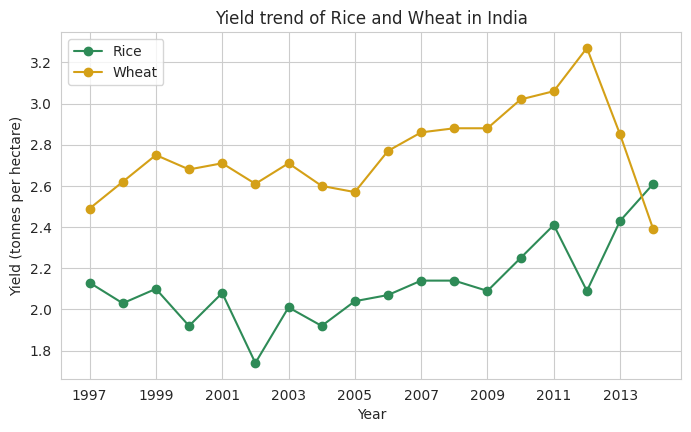

In [5]:
trend = pd.read_sql("""
    SELECT crop, year,
           ROUND(SUM(production_t) / SUM(area_ha), 2) AS yield_t_ha
    FROM crop_production
    GROUP BY crop, year
    ORDER BY crop, year
""", conn)

plt.figure(figsize=(8, 4.5))
for crop, color in [("Rice", "#2e8b57"), ("Wheat", "#d4a017")]:
    d = trend[trend["crop"] == crop]
    plt.plot(d["year"], d["yield_t_ha"], marker="o", label=crop, color=color)
plt.title("Yield trend of Rice and Wheat in India")
plt.xlabel("Year")
plt.xticks(range(1997, 2015, 2))
plt.ylabel("Yield (tonnes per hectare)")
plt.legend()
plt.show()

The wheat drop in 2013-2014 may be partly because fewer districts report data in the last years.

### 2.2 Top 5 states for each crop
This query uses the window function `RANK() OVER (PARTITION BY ...)`.

In [6]:
top = pd.read_sql("""
    SELECT * FROM (
        SELECT crop, state,
               ROUND(SUM(production_t), 0) AS total_production_t,
               RANK() OVER (PARTITION BY crop ORDER BY SUM(production_t) DESC) AS rank_in_crop
        FROM crop_production
        GROUP BY crop, state
    )
    WHERE rank_in_crop <= 5
    ORDER BY crop, rank_in_crop
""", conn)
top

,crop,state,total_production_t,rank_in_crop
0,Rice,West Bengal,"258,092,849.00",1
1,Rice,Uttar Pradesh,"218,793,359.00",2
2,Rice,Punjab,"157,828,000.00",3
3,Rice,Andhra Pradesh,"128,132,644.00",4
4,Rice,Odisha,"113,130,742.00",5
5,Sugarcane,Uttar Pradesh,"2,202,874,890.00",1
6,Sugarcane,Maharashtra,"938,485,965.00",2
7,Sugarcane,Karnataka,"515,845,482.00",3
8,Sugarcane,Tamil Nadu,"510,308,456.00",4
9,Sugarcane,Andhra Pradesh,"226,730,305.00",5


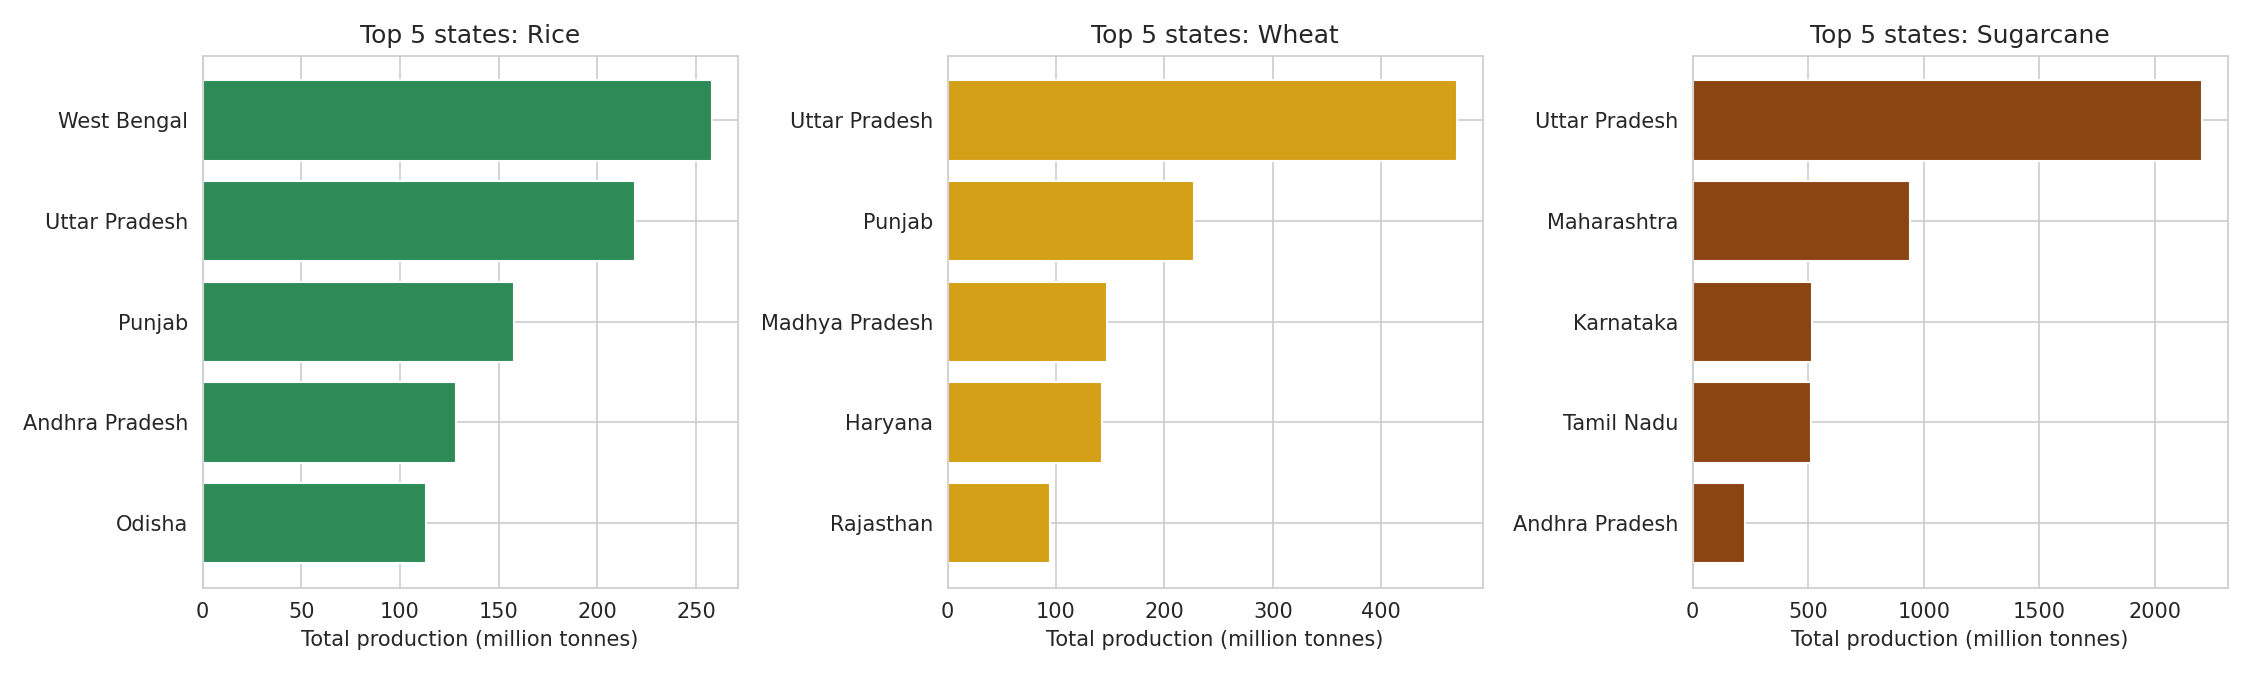

In [7]:
display(Image("outputs/charts/03_top_states_by_crop.png"))

### 2.3 Production by season

In [8]:
season = pd.read_sql("""
    SELECT crop, season,
           ROUND(SUM(production_t) / 1000000.0, 1) AS production_million_t,
           ROUND(SUM(production_t) / SUM(area_ha), 2) AS yield_t_ha
    FROM crop_production
    GROUP BY crop, season
    HAVING COUNT(*) >= 50
    ORDER BY crop, production_million_t DESC
""", conn)
season

,crop,season,production_million_t,yield_t_ha
0,Rice,Kharif,909.60,2.20
1,Rice,Winter,376.50,1.89
2,Rice,Summer,126.20,2.44
3,Rice,Rabi,68.50,3.31
4,Rice,Autumn,51.30,1.30
5,Rice,Whole Year,18.40,2.53
6,Sugarcane,Whole Year,"3,399.40",71.32
7,Sugarcane,Kharif,"1,772.60",62.70
8,Sugarcane,Winter,15.40,63.67
9,Wheat,Rabi,"1,257.30",2.77


Wheat is almost fully a Rabi crop, rice is mainly Kharif, and sugarcane is mostly a whole-year crop.

### 2.4 Which states improved their yield the most?
Compares 1998-2000 with 2012-2014 using two CTEs and a join.

In [9]:
growth = pd.read_sql("""
    WITH early AS (
        SELECT crop, state, SUM(production_t) / SUM(area_ha) AS early_yield
        FROM crop_production WHERE year BETWEEN 1998 AND 2000
        GROUP BY crop, state HAVING SUM(area_ha) > 10000
    ),
    late AS (
        SELECT crop, state, SUM(production_t) / SUM(area_ha) AS late_yield
        FROM crop_production WHERE year BETWEEN 2012 AND 2014
        GROUP BY crop, state HAVING SUM(area_ha) > 10000
    )
    SELECT e.crop, e.state,
           ROUND(e.early_yield, 2) AS yield_1998_2000,
           ROUND(l.late_yield, 2) AS yield_2012_2014,
           ROUND(100.0 * (l.late_yield - e.early_yield) / e.early_yield, 1) AS growth_percent
    FROM early e JOIN late l ON e.crop = l.crop AND e.state = l.state
    ORDER BY e.crop, growth_percent DESC
""", conn)
growth[growth["crop"] == "Rice"].head(8)

,crop,state,yield_1998_2000,yield_2012_2014,growth_percent
0,Rice,Chhattisgarh,0.63,1.91,203.90
1,Rice,Madhya Pradesh,0.74,1.71,131.80
2,Rice,Gujarat,1.33,2.14,61.10
3,Rice,Bihar,1.49,2.39,60.60
4,Rice,Meghalaya,1.57,2.40,53.00
5,Rice,Nagaland,1.50,2.27,51.40
6,Rice,Assam,1.43,2.08,44.70
7,Rice,Haryana,2.39,3.27,37.00


Some very large changes (for example Chhattisgarh) are probably caused by the state boundary change in 2000, so they should be read carefully.

### 2.5 Yield heatmap

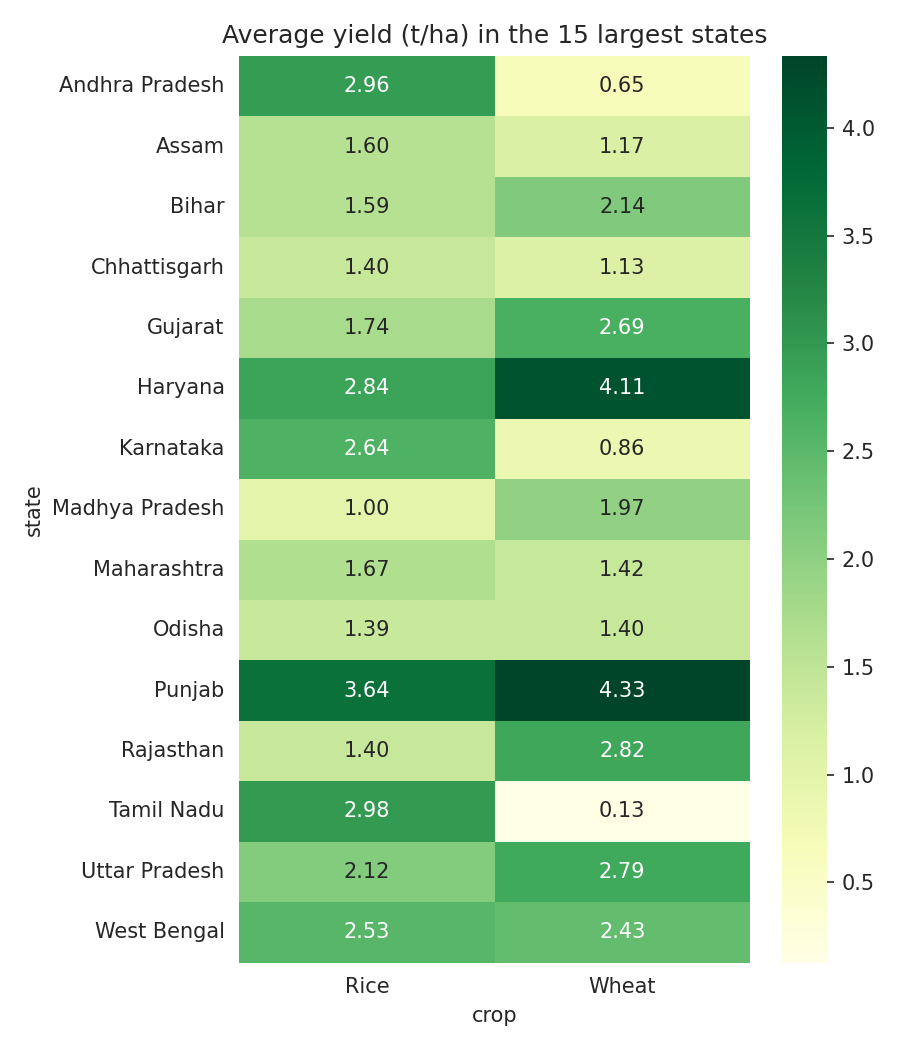

In [10]:
display(Image("outputs/charts/06_yield_heatmap.png"))

## 3. Crop recommendation model
**Goal:** predict the best crop from N, P, K, temperature, humidity, pH and rainfall.

In [11]:
rec = pd.read_sql("SELECT * FROM crop_recommendation", conn)
print(rec.shape, "| missing values:", rec.isna().sum().sum(), "| crops:", rec["label"].nunique())
rec.head()

(2200, 8) | missing values: 0 | crops: 22


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.88,82.00,6.50,202.94,rice
1,85,58,41,21.77,80.32,7.04,226.66,rice
2,60,55,44,23.00,82.32,7.84,263.96,rice
3,74,35,40,26.49,80.16,6.98,242.86,rice
4,78,42,42,20.13,81.60,7.63,262.72,rice


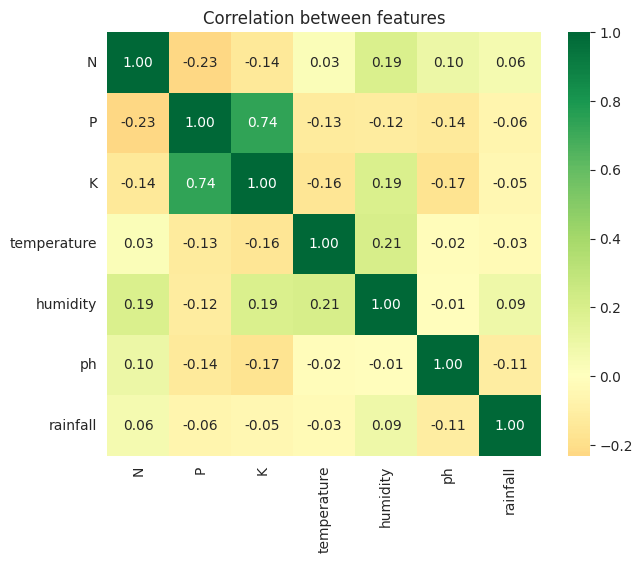

In [12]:
features = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]

plt.figure(figsize=(7, 5.5))
sns.heatmap(rec[features].corr(), annot=True, fmt=".2f", cmap="RdYlGn", center=0)
plt.title("Correlation between features")
plt.show()

P and K are strongly related (about 0.74), but the other features are mostly independent.

### Compare four models (5-fold cross validation)

Logistic Regression: 0.9676
KNN: 0.9659
Decision Tree: 0.9852


Random Forest: 0.9943


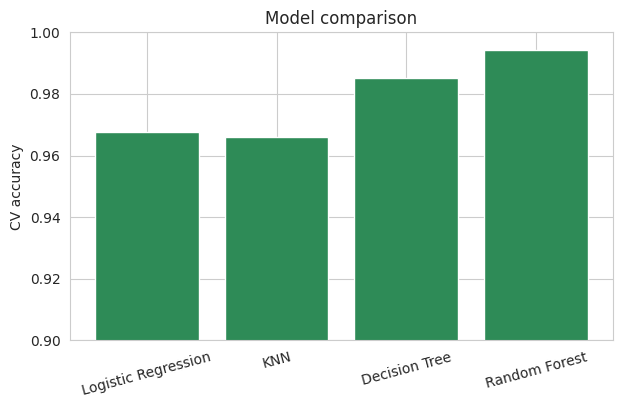

In [13]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

X = rec[features]
y = rec["label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

scores = {}
for name, model in models.items():
    scores[name] = cross_val_score(model, X_train, y_train, cv=5).mean()
    print(f"{name}: {scores[name]:.4f}")

plt.figure(figsize=(7, 4))
plt.bar(scores.keys(), scores.values(), color="#2e8b57")
plt.ylim(0.9, 1.0)
plt.ylabel("CV accuracy")
plt.xticks(rotation=15)
plt.title("Model comparison")
plt.show()

### Test the best model on unseen data

Test accuracy: 0.9955


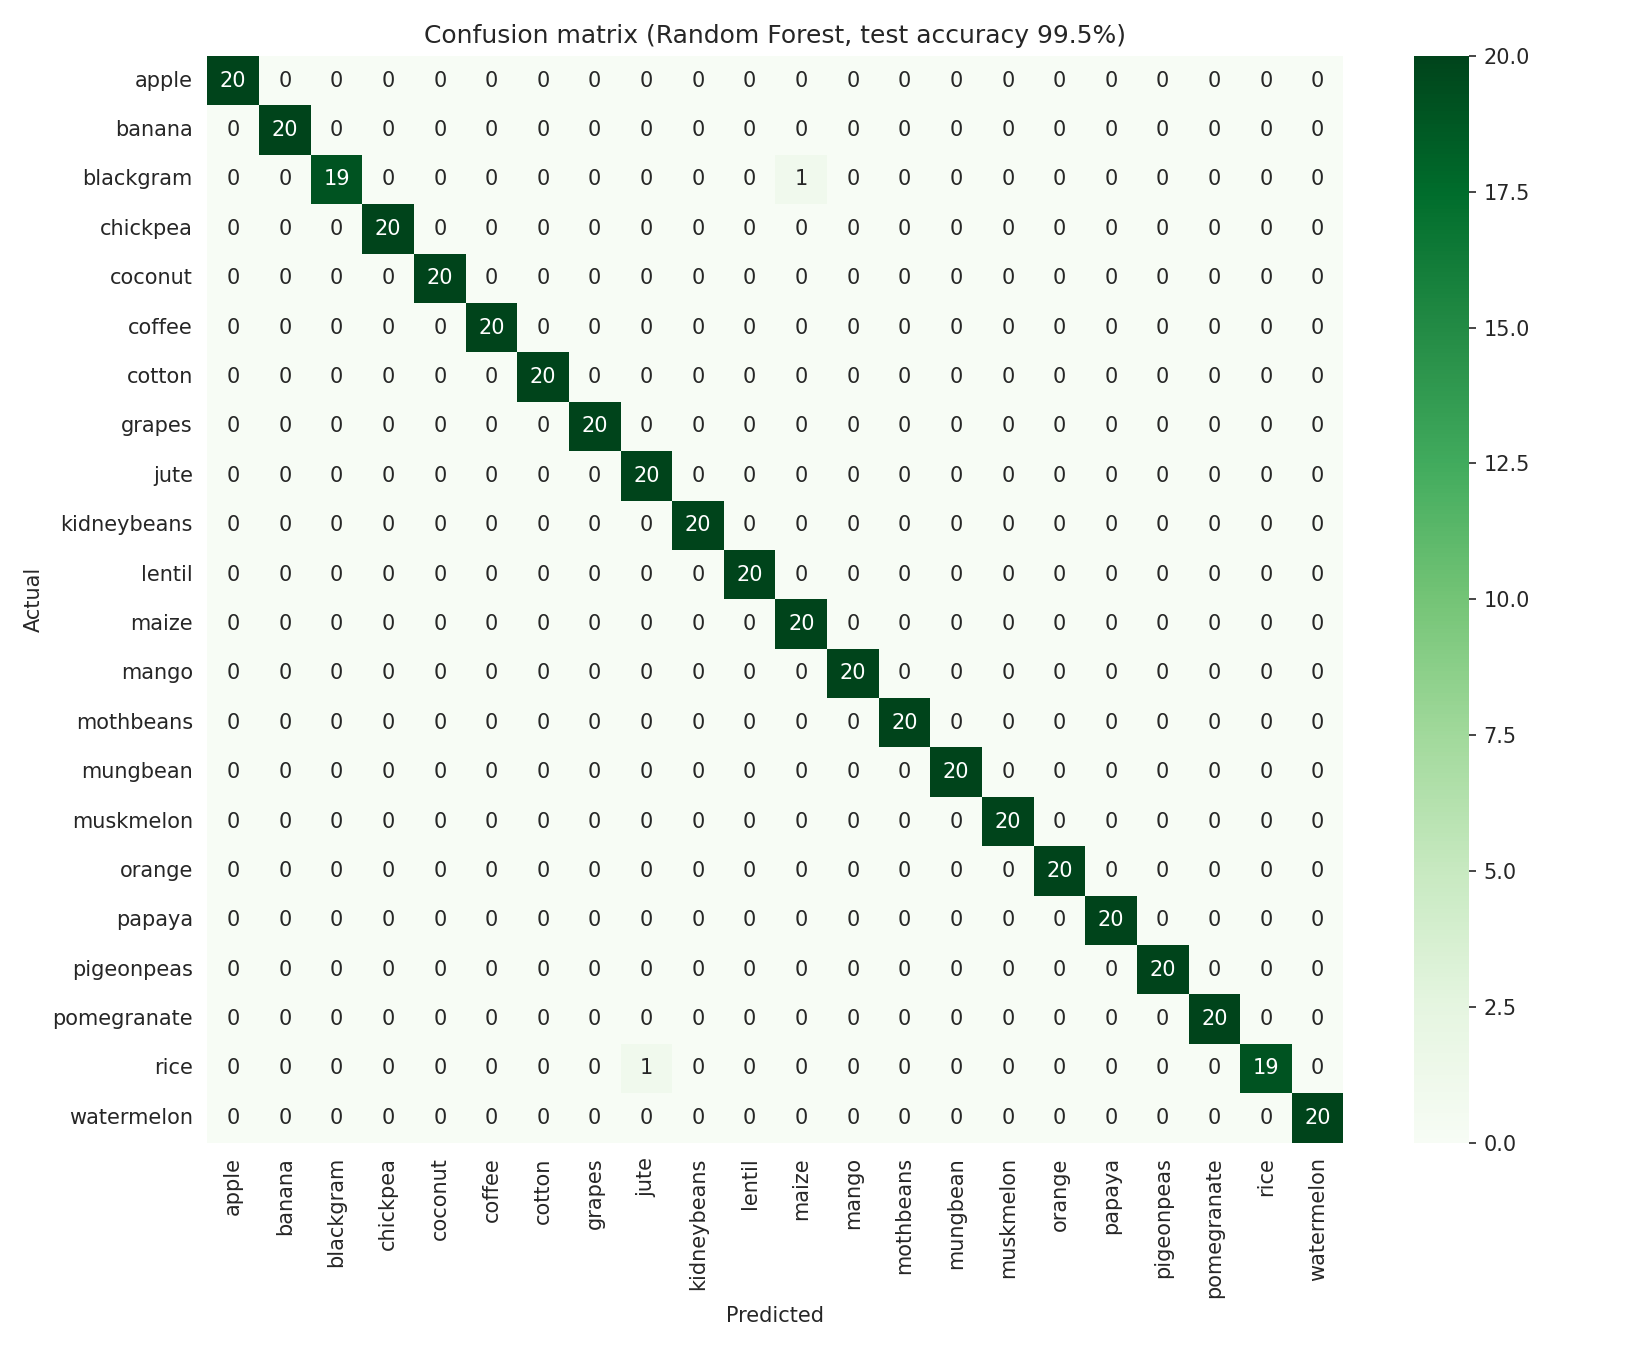

In [14]:
best = models["Random Forest"].fit(X_train, y_train)
pred = best.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, pred), 4))

display(Image("outputs/charts/10_confusion_matrix.png"))

The model rarely makes mistakes. The dataset is very clean, so real-world accuracy would be lower than this.

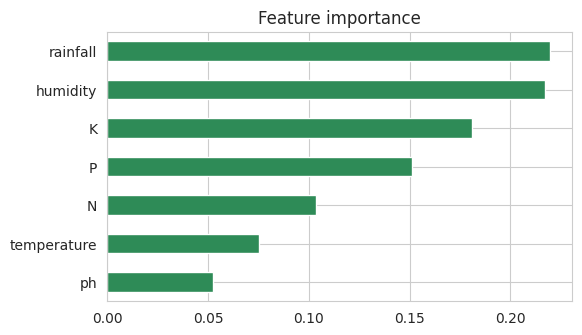

In [15]:
importance = pd.Series(best.feature_importances_, index=features).sort_values()
importance.plot(kind="barh", color="#2e8b57", figsize=(6, 3.5), title="Feature importance")
plt.show()

### Try it: which crop for these conditions?

In [16]:
saved = joblib.load("models/crop_recommender.joblib")
sample = pd.DataFrame([[90, 42, 43, 21, 82, 6.5, 203]], columns=saved["features"])
probs = pd.Series(saved["model"].predict_proba(sample)[0], index=saved["model"].classes_).sort_values(ascending=False)
print("Recommended crop:", probs.index[0])
probs.head(3)

Recommended crop: rice


rice        0.99
jute        0.01
blackgram   0.00
dtype: float64

## 4. Yield prediction model
**Goal:** predict yield (tonnes per hectare) from state, crop, season, year and area.

The model is trained on 1997-2010 and tested on 2011-2014, so the test is like predicting the future. It is compared with a simple baseline (average yield of the crop).

In [17]:
results = pd.read_csv("outputs/tables/yield_model_results.csv")
results

,Model,MAE all crops (t/ha),MAE rice+wheat (t/ha),R2 all crops
0,Baseline (crop average),6.52,0.78,0.71
1,Linear Regression,4.91,0.64,0.81
2,Random Forest,3.53,0.55,0.89


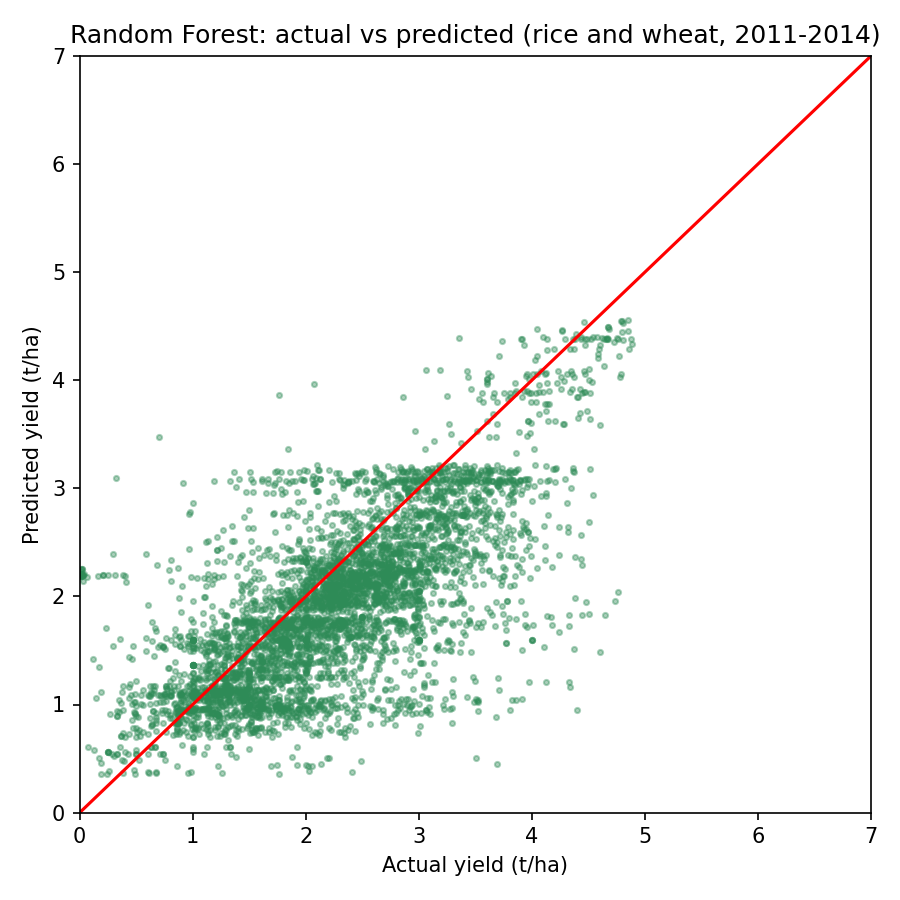

In [18]:
display(Image("outputs/charts/12_yield_actual_vs_predicted.png"))

The Random Forest is better than the baseline, but it has no weather or soil inputs, so it cannot explain bad years caused by rainfall.

### Try it: predict yield

In [19]:
ysaved = joblib.load("models/yield_model.joblib")

def predict_yield(state, crop, season, year, area):
    row = pd.DataFrame(0, index=[0], columns=ysaved["columns"])
    row["year"] = year
    row["log_area"] = np.log(area)
    for col in [f"state_{state}", f"crop_{crop}", f"season_{season}"]:
        if col in row.columns:
            row[col] = 1
    return float(np.exp(ysaved["model"].predict(row)[0]))

# (state, typical district area in hectares) - areas are taken from the data, because area is an input of the model
for state, area in [("Punjab", 100000), ("Bihar", 7000)]:
    actual = df[(df["state"] == state) & (df["crop"] == "Rice") & (df["season"] == "Kharif")]
    actual_avg = actual["production_t"].sum() / actual["area_ha"].sum()
    pred = predict_yield(state, "Rice", "Kharif", 2014, area)
    print(f"{state}: predicted {pred:.2f} t/ha | average in the data {actual_avg:.2f} t/ha")

Punjab: predicted 3.94 t/ha | average in the data 3.64 t/ha
Bihar: predicted 1.75 t/ha | average in the data 1.38 t/ha


## 5. Conclusion
- Punjab has the highest yield for both rice and wheat, and Uttar Pradesh is the largest producer of wheat and sugarcane.
- Rice and wheat yield improved slowly between 1997 and 2014.
- Rainfall, humidity and potassium are the most useful features for recommending a crop.
- The yield model beats the baseline, but adding weather data is the next step.

Run the interactive version with `streamlit run app.py`.